In [1]:
!nvidia-smi

Wed Dec 11 10:35:55 2024       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.03              Driver Version: 560.35.03      CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla P100-PCIE-16GB           Off |   00000000:00:04.0 Off |                    0 |
| N/A   29C    P0             26W /  250W |       0MiB /  16384MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import glob
import pandas as pd


train_df = pd.read_csv("/kaggle/input/nie-pdl-24-final-competition/train.csv")
test_df = pd.read_csv("/kaggle/input/nie-pdl-24-final-competition/test.csv")

lbl_map = {lbl:i for i, lbl in enumerate(sorted(set(train_df["label"])))}
print(lbl_map)

train_df["image"] = "/kaggle/input/nie-pdl-24-final-competition/images/"+ train_df["image_id"]
train_df["fold"] = train_df.index%5
test_df["image"] = "/kaggle/input/nie-pdl-24-final-competition/images/"+ test_df["image_id"]

train_df.head()

{'Andy-Warhol': 0, 'Claude-Monet': 1, 'Pablo-Picasso': 2, 'Rembrandt-Harmenszoon-van-Rijn': 3, 'Salvador-Dali': 4, 'Vincent-van-Gogh': 5}


,image_id,label,image,fold
0,2344.png,Claude-Monet,/kaggle/input/nie-pdl-24-final-competition/ima...,0
1,6366.png,Salvador-Dali,/kaggle/input/nie-pdl-24-final-competition/ima...,1
2,5133.png,Rembrandt-Harmenszoon-van-Rijn,/kaggle/input/nie-pdl-24-final-competition/ima...,2
3,3685.png,Salvador-Dali,/kaggle/input/nie-pdl-24-final-competition/ima...,3
4,6938.png,Claude-Monet,/kaggle/input/nie-pdl-24-final-competition/ima...,4


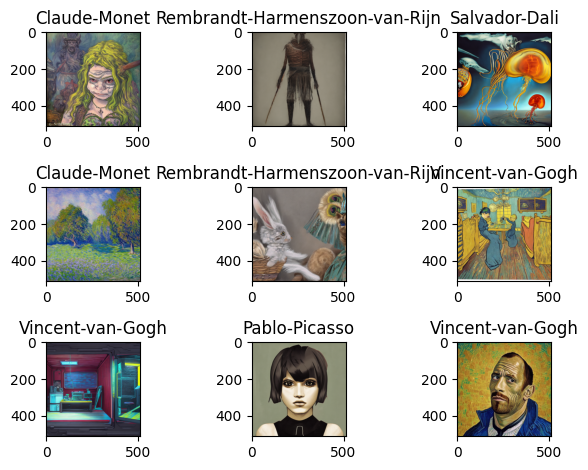

In [3]:
import matplotlib.pyplot as plt

N = 9

act_df = train_df.sample(N)
for i in range(N):
    plt.subplot( 3, 3, i+1)
    f_id, label, file, _ = act_df.iloc[i]
    plt.imshow(plt.imread(file))
    plt.title(label)

plt.tight_layout()

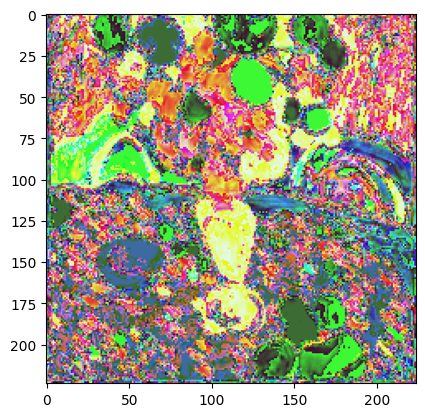

In [4]:
import torch
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import os
from transformers import AutoTokenizer
from torchvision.transforms.v2 import *
from PIL import Image
import timm
from torchvision.transforms.autoaugment import AutoAugment, AutoAugmentPolicy



auto_augment = AutoAugment(policy=AutoAugmentPolicy.CIFAR10)

# Define the Dataset class
class CustomDataset(Dataset):
    def __init__(self,  df, image_col, label_col, resolution, mode, cutmix_prob=0.5):
        self.images = df[image_col].tolist()
        self.labels = None if label_col not in df.columns else df[label_col].values.tolist()
        self.resolution = resolution
        self.cutmix_prob = cutmix_prob  # Probability of applying CutMix
        
        if mode == "train":
            self.aug =  Compose([
                Resize((resolution, resolution)),
                #RandomHorizontalFlip(p=0.5),
                auto_augment,
                PILToTensor(),
                ConvertImageDtype(),
                Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
            ])
        else:
            self.aug =  Compose([
                Resize((resolution, resolution)),
                PILToTensor(),
                ConvertImageDtype(),
                Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
            ])
            

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        x = Image.open(self.images[idx])
        x = self.aug(x)

        
        res = {"input": x}
        if self.labels is not None:
            res["target"] = torch.tensor(lbl_map[self.labels[idx]]).long()
            
        return res
    
    
batch_size=16
train_ds = CustomDataset(train_df, "image", "label", 224, "train")
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

import matplotlib.pyplot as plt

plt.imshow(ToPILImage()(train_ds[0]["input"]))

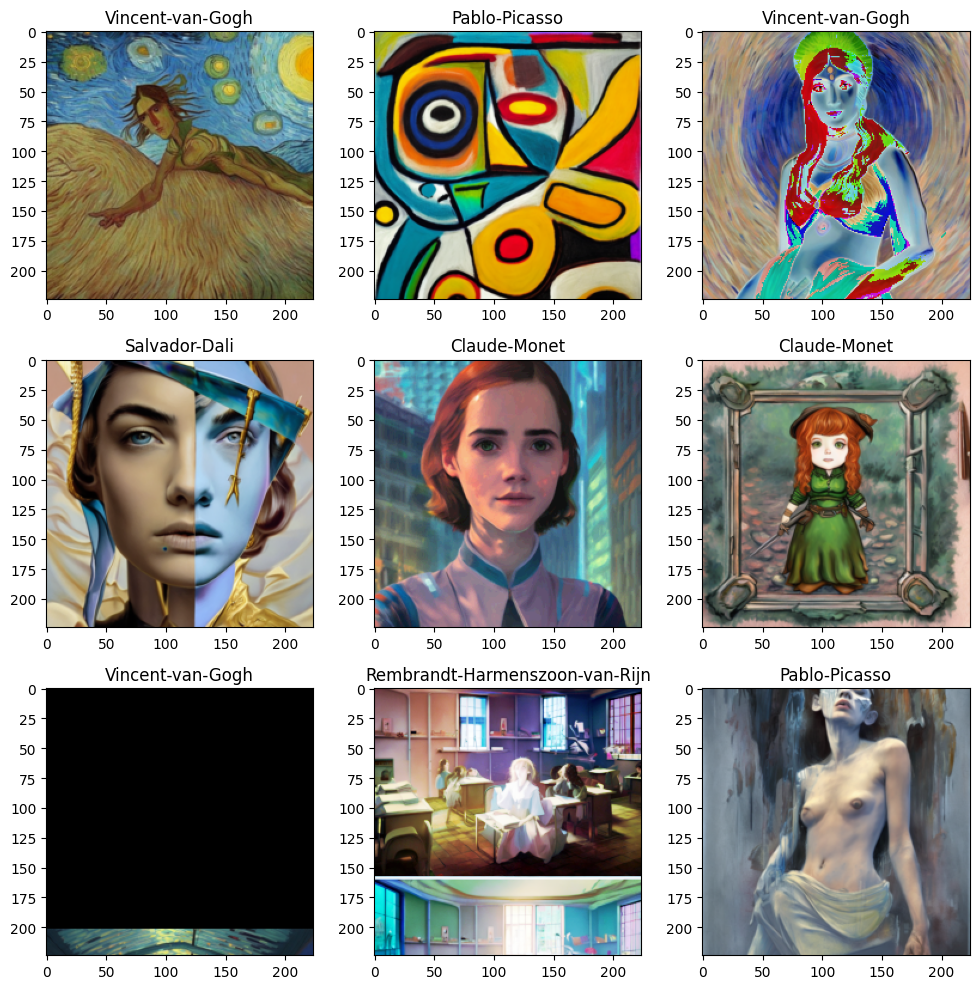

In [5]:
import numpy as np


N=9

batch = next(iter(train_dl))
inverse_lbl_map = {v:k for k,v in lbl_map.items()}

plt.figure(figsize=(10,10))
for i in range(N):
    plt.subplot( 3, 3, i+1)
    
    img = batch["input"][i]
    title = inverse_lbl_map[batch["target"][i].item()]
    img = img.permute(1,2,0)
    img *= np.array([0.229, 0.224, 0.225])
    img += np.array([0.485, 0.456, 0.406])
    plt.imshow(img)
    plt.title(title)

plt.tight_layout()

In [6]:
# from torch import nn, sigmoid, softmax


# class Head(nn.Module):
#     def __init__(self, layers, activation=nn.ReLU):
#         super().__init__()
#         my_layers = []
        
#         for i in range(len(layers)-1):
#             my_layers.append(nn.Linear(layers[i], layers[i+1]))
#             if i< len(layers)-2:
#                 my_layers.append(activation())

#         self.layers = nn.ModuleList(my_layers)
        
#     def forward(self, x):
#         for layer in self.layers:
#             x = layer(x)
#         return x


# class CustomModel(nn.Module):
#     def __init__(self, backbone, num_outputs,drop_rate=0.4, hidden_layers=None, tim_head=False):
#         super().__init__()
        
#         self.backbone_name = backbone
#         self.tim_head = tim_head
        
#         args = dict(
#             model_name=self.backbone_name,
#             pretrained=True,
#             drop_rate=drop_rate,
#             in_chans=3,
#         )
#         if not tim_head:
#             args = {"global_pool": "", "num_classes": 0, **args}
#         else:
#             args = {"num_classes": num_outputs, **args}
            
#         self.backbone = timm.create_model(**args)
        
        
#         self.pool = nn.AdaptiveAvgPool2d(1)
#         self.num_outputs = num_outputs

#         hidden_layers = hidden_layers if hidden_layers else []
#         hidden_layers = [self.backbone.num_features] + hidden_layers + [num_outputs]
#         self.head = Head(hidden_layers)
    
#     def forward(self, x, print_shapes=False, apply_softmax=False):
#         x = self.backbone(x)
        
#         if print_shapes:
#             print("Backbone output shape", x.shape)
        
#         if not self.tim_head:

#             x = self.pool(x)

#             if print_shapes:
#                 print("Pool output shape", x.shape)

#             x = x[:, :, 0 , 0]
#             if print_shapes:
#                 print("Pool output flattened", x.shape)

#             x = self.head(x)
#             if print_shapes:
#                 print("Head output shape", x.shape)
            
#         if apply_softmax:
#             x = softmax(x, 1)
            
#         # reduce single dimension
#         if self.num_outputs == 1:
#             x = x.view(-1)
            
#         return x




In [7]:
from torch import nn, sigmoid, softmax
import torch


# Gem Pooling Function
def gem_pooling(feature_map, query_vector=None, alpha=0.1):
    """
    Computes Gem Pooling over a feature map.
    
    Args:
        feature_map (torch.Tensor): Input feature map from shape (batch_size, channels, height, width).
        query_vector (torch.Tensor): A query vector, usually computed globally or from the embedding (optional).
        alpha (float): A smoothing parameter for balancing the query and feature aggregation.

    Returns:
        pooled_features (torch.Tensor): Result of the gem pooling operation with shape (batch_size, channels).
    """
    # Flatten spatial dimensions
    batch_size, channels, height, width = feature_map.shape
    feature_map_flattened = feature_map.view(batch_size, channels, -1)  # Shape: (batch_size, channels, height * width)
    
    # Compute the query vector (use global average if none provided)
    if query_vector is None:
        query_vector = torch.mean(feature_map_flattened, dim=2, keepdim=True)  # Shape: (batch_size, channels, 1)

    # Compute similarity (weighted pooling)
    similarity = torch.bmm(query_vector.transpose(1, 2), feature_map_flattened)  # Shape: (batch_size, 1, height * width)
    weights = torch.softmax(similarity, dim=-1)  # Normalize weights over spatial dimensions
    weighted_features = torch.bmm(weights, feature_map_flattened.transpose(1, 2)).squeeze(1)  # Shape: (batch_size, channels)

    # Smooth weighted features
    pooled_features = alpha * query_vector.squeeze(2) + (1 - alpha) * weighted_features  # Shape: (batch_size, channels)
    
    return pooled_features


class Head(nn.Module):
    def __init__(self, layers, activation=nn.ReLU):
        """
        Head class with Dropout added after each Linear layer for regularization.
        
        Args:
            layers (list): List of dimensions for each layer.
            activation (nn.Module): Activation function (default is ReLU).
            drop_rate (float): Dropout rate to apply after each layer.
        """
        super().__init__()
        my_layers = []
        
        for i in range(len(layers) - 1):
            my_layers.append(nn.Linear(layers[i], layers[i+1]))
            my_layers.append(activation())
            my_layers.append(nn.Dropout(p=0.2))

        self.layers = nn.ModuleList(my_layers)
        
    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x


class CustomModel(nn.Module):
    def __init__(self, backbone, num_outputs, hidden_layers=None, tim_head=False):
        """
        Custom Model incorporating Dropout after backbone output and using Gem Pooling or Head as needed.
        
        Args:
            backbone (str): Backbone model name.
            num_outputs (int): Number of classification outputs.
            drop_rate (float): Dropout rate to use after backbone outputs and within Head layers.
            hidden_layers (list): List of hidden layer sizes.
            tim_head (bool): Whether to use a head directly tied to timm's standard model head.
        """
        super().__init__()
        
        self.backbone_name = backbone
        self.tim_head = tim_head
        
        args = dict(
            model_name=self.backbone_name,
            pretrained=True,
            in_chans=3,
        )
        if not tim_head:
            args = {"global_pool": "", "num_classes": 0, **args}
        else:
            args = {"num_classes": num_outputs, **args}
            
        self.backbone = timm.create_model(**args)
        
        self.num_outputs = num_outputs

        hidden_layers = hidden_layers if hidden_layers else []
        hidden_layers = [self.backbone.num_features] + hidden_layers + [num_outputs]
        self.head = Head(hidden_layers)

    def forward(self, x, print_shapes=False, apply_softmax=False):
        """
        Forward pass with optional softmax and dropout.
        
        Args:
            x (torch.Tensor): Input data tensor.
            print_shapes (bool): If True, prints intermediate tensor shapes.
            apply_softmax (bool): If True, applies softmax to model predictions.

        Returns:
            Output tensor from model.
        """
        x = self.backbone(x)
        
        if print_shapes:
            print("Backbone output shape", x.shape)

        if not self.tim_head:
            # Apply Gem Pooling instead of AdaptiveAvgPool2d
            pooled_features = gem_pooling(x)

            if print_shapes:
                print("Pooled features after gem pooling", pooled_features.shape)

            x = self.head(pooled_features)

            if print_shapes:
                print("Head output shape", x.shape)

        if apply_softmax:
            x = softmax(x, dim=1)

        # Reduce single dimension for single output case
        if self.num_outputs == 1:
            x = x.view(-1)

        return x


In [8]:
from sklearn.metrics import roc_auc_score, accuracy_score, log_loss
from transformers import get_cosine_schedule_with_warmup
from tqdm import tqdm
from torch import autocast
import random

def accuracy(x, y):
    return accuracy_score(x, np.array(y).argmax(axis=1))


def train_loop(train_dl, model, loss_fn, optimizer, scheduler, device, scaler, log_every=1, cutmix_or_mixup=0.3):
    losses = []
    lr_values = []
    size = len(train_dl)
    
    # Set the model to training mode - important for batch normalization and dropout layers
    # Unnecessary in this situation but added for best practices
    model.train()
     
    pbar = tqdm(train_dl)
    for batch_idx, batch_dict in enumerate(pbar):
        optimizer.zero_grad()

        x = batch_dict["input"]
        x = x.to(device)

        y = batch_dict["target"].long().to(device)

        if cutmix_or_mixup is not None and random.random() < 0.6:
             x, y = cutmix_or_mixup(x, y)
        
        with autocast(device_type='cuda', dtype=torch.float16):
            # Compute prediction and loss
            pred = model(x)
            loss = loss_fn(pred, y)

        # Backpropagation
        # Scales loss.  Calls backward() on scaled loss to create scaled gradients.
        # Backward passes under autocast are not recommended.
        # Backward ops run in the same dtype autocast chose for corresponding forward ops.
        scaler.scale(loss).backward()

        # scaler.step() first unscales the gradients of the optimizer's assigned params.
        # If these gradients do not contain infs or NaNs, optimizer.step() is then called,
        # otherwise, optimizer.step() is skipped.
        scaler.step(optimizer)

        # Updates the scale for next iteration.
        scaler.update()
        
        scheduler.step()
        
        if batch_idx % log_every == 0:
            losses.append(loss.detach().cpu().item())
            lr_values.append(scheduler.get_last_lr()[0])
        
        loss, current = loss.item(), (batch_idx + 1)
        pbar.set_description(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
            
    return losses, lr_values


# def inference_loop(model, dataloader, device, **predict_kwargs):
#     model.to(device)
#     predictions = []
#     labels = []
    
#     # Set the model to evaluation mode - important for batch normalization and dropout layers
#     model.eval()
    
#     # Evaluating the model with torch.no_grad() ensures that no gradients are computed during test mode
#     # also serves to reduce unnecessary gradient computations and memory usage for tensors with requires_grad=True
#     with torch.no_grad():
#         for batch_dict in tqdm(dataloader):
#             x = batch_dict["input"]
#             x = x.to(device)
#             y = batch_dict.get("target")
            
#             with autocast(device_type='cuda', dtype=torch.float16):
#                 pred = model(x, **predict_kwargs)

#             # we move predictions to cpu, in case they are stored on GPU
#             predictions.extend(pred.cpu().tolist())
            
#             if y is not None:
#                 labels.extend(y.cpu().tolist())
                
#     return predictions, labels


def inference_loop(model, dataloader, device, use_tta=False, **predict_kwargs):
    """
    Model inference loop with optional Test-Time Augmentation (TTA) applied to each image in the dataloader.
    Args:
        model: Model instance
        dataloader: DataLoader instance for test/validation
        device: Device to compute on
        use_tta: Whether to apply TTA logic
        **predict_kwargs: Additional parameters passed to model's forward pass
    Returns:
        List of predictions and optional labels.
    """
    model.to(device)
    predictions = []
    labels = []

    model.eval()
    with torch.no_grad():
        for batch_dict in tqdm(dataloader):
            x = batch_dict["input"].to(device)  # Move input batch to device
            y = batch_dict.get("target")
            
            if use_tta:
                # Loop over each image in the batch and apply augmentations
                batch_preds = []
                for img in x:  # Process each image independently
                    augmented_images = tta_augmentations(img.cpu())  # Perform TTA augmentations
                    augmented_preds = []
                    for augmented_img in augmented_images:
                        augmented_img = torch.tensor(augmented_img, dtype=torch.float32).to(device)
                        augmented_img = augmented_img.unsqueeze(0)  # Add batch dimension
                        with autocast(device_type='cuda', dtype=torch.float16):
                            pred = model(augmented_img, **predict_kwargs)
                            augmented_preds.append(pred.cpu().tolist())
                    
                    # Average predictions across all augmentations
                    avg_pred = np.mean(augmented_preds, axis=0)
                    batch_preds.append(avg_pred)
                predictions.extend(batch_preds)
            else:
                # Perform a direct forward pass without augmentations
                with autocast(device_type='cuda', dtype=torch.float16):
                    pred = model(x, **predict_kwargs)
                    predictions.extend(pred.cpu().tolist())

            # Collect labels if provided
            if y is not None:
                labels.extend(y.cpu().tolist())

    return predictions, labels


def validation_loop(val_dl, model, val_metrics, device):
    predictions, labels = inference_loop(model, val_dl, device, use_tta=False, apply_softmax=True)
    scores = {metric.__name__: metric(labels, predictions) for metric in val_metrics}
    return scores


def predict(model, test_dl, device, apply_softmax=True):
    model.to(device)
    predictions, _ = inference_loop(model, test_dl, device, use_tta=True, apply_softmax=apply_softmax)
    return predictions


def train(model, train_dl, val_dl, loss, optimizer, scheduler, epochs, val_metrics, device, scaler, cutmix_or_mixup=None):
    scores = []
    losses = []
    lr_rates = []
    
    model.to(device)
    
    for epoch in range(epochs):
        print(f"Epoch {epoch+1}/{epochs}\n-------------------------------")
        epoch_losses, epoch_lr_rates = train_loop(train_dl, model, loss, optimizer, scheduler, device, scaler,1, cutmix_or_mixup)
        epoch_scores = validation_loop(val_dl, model, val_metrics, device)
        print(epoch_scores)
        scores.append(epoch_scores)
        losses.extend(epoch_losses)
        lr_rates.extend(epoch_lr_rates)
    print("Done!")
    return model, scores, losses, lr_rates


from torchvision import transforms
import numpy as np
from torch import autocast

def tta_augmentations(image):
    """
    Apply a series of augmentations for TTA.
    Args:
        image (torch.Tensor): Input image tensor of shape (C, H, W).
    Returns:
        list of augmented images.
    """
    augmentations = [
        # transforms.Compose([
        #     transforms.RandomHorizontalFlip(p=1.0),
        #     transforms.RandomRotation(degrees=5),
        #     transforms.ColorJitter(brightness=0.2, contrast=0.2),
        # ]),
        transforms.Compose([
            transforms.RandomHorizontalFlip(p=1.0)
        ]),
        # transforms.Compose([
        #     transforms.RandomRotation(degrees=10),
        # ]),
        transforms.Compose([]),  # Original image without augmentations
    ]
    
    augmented_images = []
    for aug in augmentations:
        augmented_img = aug(image)
        augmented_images.append(augmented_img)

    return augmented_images

In [9]:
# import random
# import v2 

# # Initialize CutMix and MixUp
# cutmix = v2.CutMix(num_classes=NUM_CLASSES)
# mixup = v2.MixUp(num_classes=NUM_CLASSES)

# # Randomly choose between CutMix and MixUp for each batch
# cutmix_or_mixup = v2.RandomChoice([cutmix, mixup])



# # Specify all hyper-parameters
# backbone = "timm/tf_efficientnetv2_b0.in1k"
# image_size = 512

# learning_rate = 3e-4
# num_classes = 6
# hidden_layers = None
# epochs = 5
# batch_size = 32
# device = "cuda"
# tim_head = True

# val_metrics = [accuracy, log_loss]
# loss = nn.CrossEntropyLoss()
# model = CustomModel(backbone, num_classes, hidden_layers, tim_head=tim_head)
# optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

# # Creates a GradScaler once at the beginning of training.
# scaler = torch.cuda.amp.GradScaler()

# sample_size = None

# act_train = train_df.query("fold!=0")
# act_val = train_df.query("fold==0")

# if sample_size:
#     act_train = act_train.head(sample_size)
#     act_val = act_val.head(sample_size)

# # Get datasets and data loaders
# train_ds = CustomDataset(act_train, "image", "label", image_size, "train")
# train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=4)

# val_ds = CustomDataset(act_val, "image", "label", image_size, "test")
# val_dl = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=4)

# # Get scheduler
# scheduler = get_cosine_schedule_with_warmup(
#     optimizer, num_warmup_steps=0, num_training_steps=epochs * len(train_dl)
# )

# # Train model
# model, val_scores, train_losses, lr_rates = train(
#     model, train_dl, val_dl, loss, optimizer, scheduler, epochs, val_metrics, device, scaler
# )

# # Save model weights
# # torch.save(model.state_dict(), 'model_weights.pth')

# # Plot Learning Rates
# pd.DataFrame({"Learning rate":lr_rates}).plot(xlabel="step", ylabel="lr", style="-", title="Train")

# # Plot Train Losses
# pd.DataFrame({"train loss":train_losses}).plot(xlabel="step", ylabel="loss", style="-", title="Train")

# # Plot Validation Metrics
# pd.DataFrame(val_scores).plot(xlabel="epoch", ylabel="score", style="o-", title="Validation")

# # Show validation metrics
# val_scores_df = pd.DataFrame(val_scores)
# val_scores_df.index.name = "epoch"
# val_scores_df

In [10]:
import gc
gc.collect()
torch.cuda.empty_cache()

model.safetensors:   0%|          | 0.00/348M [00:00<?, ?B/s]

Epoch 1/15
-------------------------------


100%|██████████| 81/81 [00:54<00:00,  1.48it/s]


{'accuracy': 0.7727975270479135, 'log_loss': 0.765128699282923}
Epoch 2/15
-------------------------------


100%|██████████| 81/81 [00:54<00:00,  1.48it/s]


...

100%|██████████| 81/81 [00:54<00:00,  1.48it/s]


{'accuracy': 0.8554868624420402, 'log_loss': 0.5119795519984252}
Epoch 15/15
-------------------------------


100%|██████████| 81/81 [00:54<00:00,  1.48it/s]


{'accuracy': 0.8547140649149922, 'log_loss': 0.5114512919603365}
Done!


,accuracy,log_loss
epoch,,
0,0.772798,0.765129
1,0.785935,0.647306
2,0.808346,0.544372
3,0.787481,0.611814
4,0.809119,0.588115
5,0.846986,0.475437
6,0.839258,0.506879
7,0.841577,0.524707
8,0.836940,0.522964


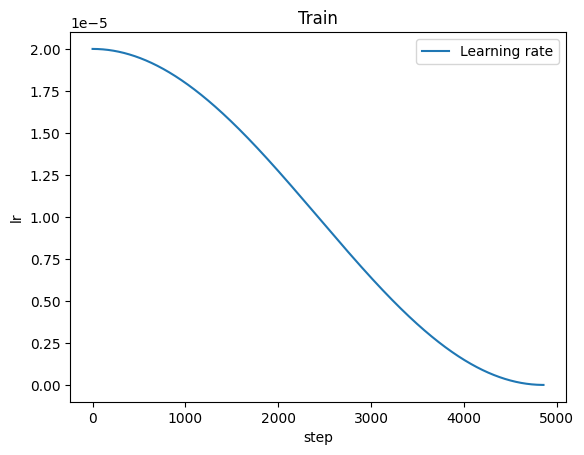

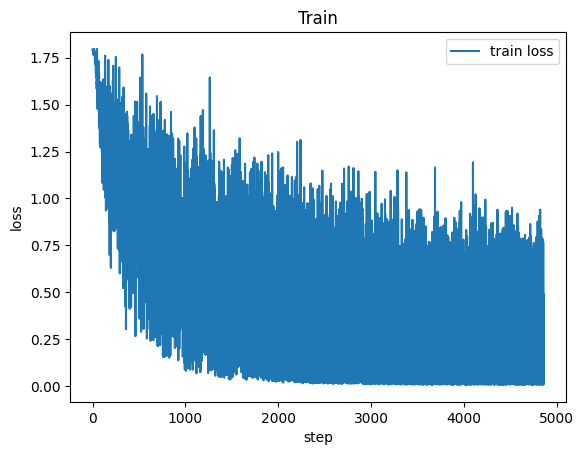

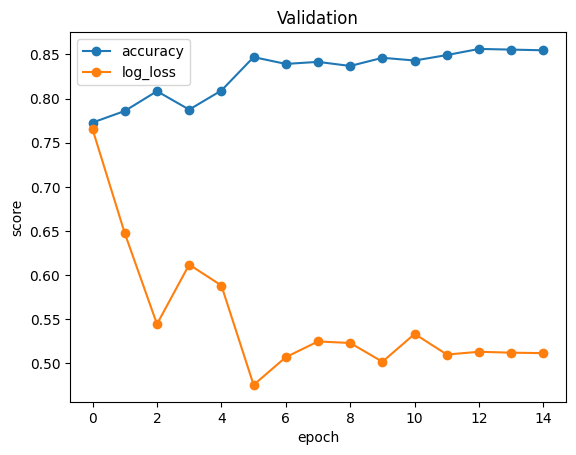

In [11]:
from torchvision.datasets import FakeData
from torchvision.transforms import v2

# Specify all hyper-parameters
backbone = "timm/eva02_base_patch14_448.mim_in22k_ft_in22k_in1k"
#timm/vit_base_patch16_clip_224.openai_ft_in12k
#timm/eva02_base_patch14_448.mim_in22k_ft_in22k_in1k
#timm/eva02_small_patch14_336.mim_in22k_ft_in1k
#timm/eva02_large_patch14_448.mim_in22k_ft_in22k_in1k
#timm/efficientnet_b4.ra2_in1k
#timm/tf_efficientnetv2_xl.in21k_ft_in1k
#timm/vit_large_patch14_clip_224.openai_ft_in12k

image_size = 448

learning_rate = 2e-5
num_classes = 6
hidden_layers = None
epochs = 15
batch_size = 16
device = "cuda"
tim_head = True

cutmix = v2.CutMix(num_classes=num_classes)
mixup = v2.MixUp(num_classes=num_classes)
#cutmix_or_mixup = v2.RandomChoice([cutmix, mixup])
cutmix_or_mixup = cutmix
#cutmix_or_mixup = None


val_metrics = [accuracy, log_loss]
loss = nn.CrossEntropyLoss()
model = CustomModel(backbone, num_classes, hidden_layers, tim_head=tim_head)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

# Creates a GradScaler once at the beginning of training.
#scaler = torch.cuda.amp.GradScaler()
scaler = torch.amp.GradScaler('cuda')

sample_size = None

act_train = train_df.query("fold!=0")
act_val = train_df.query("fold==0")

if sample_size:
    act_train = act_train.head(sample_size)
    act_val = act_val.head(sample_size)

# Get datasets and data loaders
train_ds = CustomDataset(act_train, "image", "label", image_size, "train")
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=4)

val_ds = CustomDataset(act_val, "image", "label", image_size, "test")
val_dl = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=4)

# Get scheduler
scheduler = get_cosine_schedule_with_warmup(
    optimizer, num_warmup_steps=0, num_training_steps=epochs * len(train_dl)
)

# Train model
model, val_scores, train_losses, lr_rates = train(
    model, train_dl, val_dl, loss, optimizer, scheduler, epochs, val_metrics, device, scaler, cutmix_or_mixup=cutmix_or_mixup
)

# Save model weights
# torch.save(model.state_dict(), 'model_weights.pth')

# Plot Learning Rates
pd.DataFrame({"Learning rate":lr_rates}).plot(xlabel="step", ylabel="lr", style="-", title="Train")

# Plot Train Losses
pd.DataFrame({"train loss":train_losses}).plot(xlabel="step", ylabel="loss", style="-", title="Train")

# Plot Validation Metrics
pd.DataFrame(val_scores).plot(xlabel="epoch", ylabel="score", style="o-", title="Validation")

# Show validation metrics
val_scores_df = pd.DataFrame(val_scores)
val_scores_df.index.name = "epoch"
val_scores_df

In [12]:
# Get test dataset and data loader
test_ds = CustomDataset(test_df, "image", "label", image_size, "test")
test_dl = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

test_ds_ag = CustomDataset(test_df, "image", "label", image_size, "test_ag")
test_dl_ag = DataLoader(test_ds_ag, batch_size=batch_size, shuffle=False)

# Set model to inference mode
model.eval()

# Predict on test data
preds = predict(model, test_dl, "cuda")
preds = np.array(preds)

# Preds flipped
# preds_dl = predict(model, test_dl_ag, "cuda")
# preds_dl = np.array(preds_dl)

# Averadge and combine preds
#preds = (preds + preds_dl)/2

# Compute class predictions by finding argmax along axis=1
preds = preds.squeeze(1)
pred_labels = preds.argmax(axis=1)  # Ensure this is a 1D array with shape (num_samples,)
print(preds.shape)  # Should show (num_samples, num_classes)
print(preds.argmax(axis=1).shape)  # Should show (num_samples,)

# Map predictions using the inverse label map
sub = test_df[["image_id"]].copy()
sub["label"] = pred_labels
sub["label"] = sub["label"].map(inverse_lbl_map)  # Map safely


# sub = test_df[["image_id"]].copy()
# sub["label"] = preds.argmax(axis=1)
# sub["label"] = sub["label"].map(inverse_lbl_map)

score = round(val_scores_df.iloc[-1,0],4)
path = f"sub_{score}.csv"
print(path)
sub.to_csv(path, index=False)

path = f"proba_{score}.csv"
print(path)
proba = pd.DataFrame(preds, columns = lbl_map.keys())
proba = pd.concat([test_df[["image_id"]],proba], axis=1)
proba.to_csv(path, index=False)

display(proba.head())
sub.head()

  0%|          | 0/125 [00:00<?, ?it/s]/tmp/ipykernel_23/572268067.py:120: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  augmented_img = torch.tensor(augmented_img, dtype=torch.float32).to(device)
100%|██████████| 125/125 [04:39<00:00,  2.24s/it]

(2000, 6)
(2000,)
sub_0.8547.csv
proba_0.8547.csv


,image_id,Andy-Warhol,Claude-Monet,Pablo-Picasso,Rembrandt-Harmenszoon-van-Rijn,Salvador-Dali,Vincent-van-Gogh
0,6188.png,0.001439,0.001900,0.001608,0.991476,0.001839,0.001739
1,4895.png,0.004630,0.001835,0.987450,0.001315,0.001612,0.003158
2,7716.png,0.001499,0.002732,0.000647,0.002097,0.000661,0.992365
3,4180.png,0.002473,0.982279,0.003673,0.004621,0.003002,0.003951
4,5261.png,0.990091,0.002048,0.001474,0.001581,0.001926,0.002880


,image_id,label
0,6188.png,Rembrandt-Harmenszoon-van-Rijn
1,4895.png,Pablo-Picasso
2,7716.png,Vincent-van-Gogh
3,4180.png,Claude-Monet
4,5261.png,Andy-Warhol


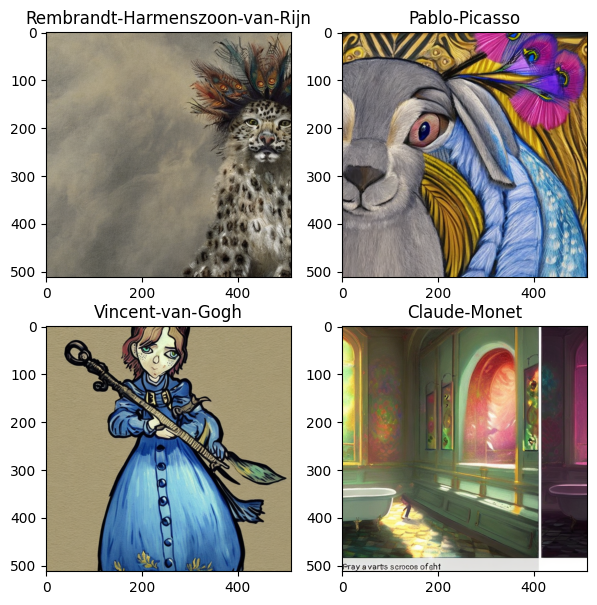

In [13]:
plt.figure(figsize=(7,7))
for i in range(4):
    plt.subplot(2,2,i+1)
    plt.imshow(plt.imread(test_df["image"][i]))
    plt.title(sub['label'].iloc[i])

In [14]:
sub.to_csv("submission.csv", index=False)